# INF605 Group 1: Color Quantization (Median Cut)

**Paper:** Heckbert, P. (1982). *Color Image Quantization for Frame Buffer Display.* Computer Graphics 16(3).

This notebook joins the five tasks of Phase A (reading and histogram) and Phase B (median cut palette selection) into one pipeline:

| Task | Step | Author |
|---|---|---|
| 1 | Read the image and flatten it to an `(N, 3)` pixel array | Gizem Bayram |
| 2 | 15-bit pre-quantization and color histogram | Salih Enes Akdere |
| 3 | Bounding box and split axis | Ceren Tayran |
| 4 | Radix list sort and weighted median split | Elif Hilal Kırer |
| 5 | Box orchestration and final palette | Fatma Hepsen Çakır |

```
image path -> [Task 1] pixels (N, 3) -> [Task 2] colors (M, 3) + counts (M,)
           -> [Task 5] loop { [Task 3] axis -> [Task 4] two boxes } -> palette (K, 3)
```

Each task has its own section with its functions and its tests. The last section runs the full pipeline on a real photo.

## Setup

All imports are collected here. `IMAGE_PATH` is the test photo and `K` is the number of palette colors used in the full pipeline at the end.

**Test image:** `kodim23.png` (two parrots, 768 × 512, 24-bit) from the Kodak Lossless True Color Image Suite, a standard test set released by Eastman Kodak for unrestricted use. Source: [r0k.us/graphics/kodak](https://r0k.us/graphics/kodak/). It is stored as PNG because PNG is lossless; a JPEG would already have changed the colors before our method runs.

In [3]:
from collections import deque
from itertools import product
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_PATH = Path("kodim23.png")   # test photo, in the same folder as this notebook
K = 256                         # number of colors in the palette

## Task 1: Image Reading and Flattening

*Author: Gizem Bayram*

The image is opened with Pillow, converted to RGB and stored as a `uint8` array of shape `(height, width, 3)`. For the pixel-based steps that follow, it is flattened to `(N, 3)`, one row per pixel.

**Input:** path of the image file.
**Output:** `(N, 3)` array with values 0 to 255.

In [5]:
def load_rgb_image(image_path: Path) -> np.ndarray:
    # The input is a file path; the output is an RGB array of shape (height, width, 3).
    try:
        with Image.open(image_path) as image:
            # Convert the image to three-channel RGB.
            with image.convert("RGB") as rgb_image:
                # uint8 stores each RGB channel in the range 0-255.
                pixels = np.array(rgb_image, dtype=np.uint8)
    except OSError as error:
        raise ValueError(f"Could not read the image: {image_path} ({error})") from error

    # Check that the RGB output has the expected height-width-channel structure.
    if pixels.ndim != 3 or pixels.shape[2] != 3:
        raise ValueError(f"Unexpected matrix shape for an RGB image: {pixels.shape}")

    return pixels


def flatten_pixels(rgb_matrix: np.ndarray) -> np.ndarray:
    # Check that the matrix is in RGB form before flattening.
    if rgb_matrix.ndim != 3 or rgb_matrix.shape[2] != 3:
        raise ValueError(
            "The input for flattening must have shape (height, width, 3)."
        )

    # -1 lets NumPy compute the number of pixels; each row is one RGB pixel.
    return rgb_matrix.reshape(-1, 3)

## Task 2: 15-bit Quantization and Histogram

*Author: Salih Enes Akdere*

Following the paper, each channel is reduced from 8 to 5 bits with a bit shift, so the color space shrinks from 24 to 15 bits (32768 possible colors). The pixels are then counted in a histogram of length 32768, and only the colors that actually occur are kept.

**Input:** `(N, 3)` pixel array.
**Output:** `colors` of shape `(M, 3)` with values 0 to 31, and `counts` of shape `(M,)` with the number of pixels of each color.

In [7]:
def quantize_and_histogram(pixels):
    """
    Task 2: 15-bit pre-quantization and color histogram (Heckbert, 1982).

    Parameters
    ----------
    pixels : np.ndarray, shape (N, 3), values 0-255
        Flattened RGB pixels (output of Task 1).

    Returns
    -------
    colors : np.ndarray, shape (M, 3), values 0-31
        Unique 5-bit-per-channel colors that appear in the image.
    counts : np.ndarray, shape (M,)
        Number of pixels of each color (frequency weights).
    """
    pixels = np.asarray(pixels)
    if pixels.ndim != 2 or pixels.shape[1] != 3:
        raise ValueError("pixels must have shape (N, 3), got %s" % (pixels.shape,))

    # uint8 cannot hold r5 << 10 (max 31744), so we use a wider type
    p = pixels.astype(np.uint16)

    # 8 bit -> 5 bit per channel: drop the 3 least significant bits
    r5 = p[:, 0] >> 3
    g5 = p[:, 1] >> 3
    b5 = p[:, 2] >> 3

    # pack the three 5-bit values into one 15-bit index (0 .. 32767)
    index = (r5 << 10) | (g5 << 5) | b5

    # 32768-bin histogram: hist[i] = number of pixels with color index i
    hist = np.bincount(index, minlength=32768)

    # keep only the colors that actually appear
    idx = np.nonzero(hist)[0]

    # unpack each index back into (r5, g5, b5)
    colors = np.stack([(idx >> 10) & 31, (idx >> 5) & 31, idx & 31], axis=1)
    counts = hist[idx]
    return colors, counts


def to_8bit(colors5):
    """Map 5-bit colors (0-31) back to the 0-255 range (center of each bin)."""
    return (np.asarray(colors5) * 8 + 4).astype(np.uint8)

### Tests for Task 2

In [9]:
# Test 1: small hand-made example
px = np.array([[255, 255, 255],
               [0, 0, 0],
               [7, 7, 7],      # 7>>3 = 0, so the same bin as (0,0,0)
               [8, 0, 0],      # 8>>3 = 1
               [255, 255, 255]], dtype=np.uint8)
colors, counts = quantize_and_histogram(px)
print(colors)   # [[0 0 0] [1 0 0] [31 31 31]]
print(counts)   # [2 1 2]
assert counts.sum() == len(px)

# Test 2: mock data from the brief
mock = np.random.randint(0, 256, (50, 3))
colors, counts = quantize_and_histogram(mock)
assert counts.sum() == 50
assert colors.min() >= 0 and colors.max() <= 31

# Test 3: a wrong shape must raise an error
try:
    quantize_and_histogram(np.zeros((10, 4)))
    print("HATA: exception bekleniyordu")
except ValueError:
    print("Shape check works")

print("All tests passed")

[[ 0  0  0]
 [ 1  0  0]
 [31 31 31]]
[2 1 2]
Shape check works
All tests passed


## Task 3: Bounding Box and Split Axis

*Author: Ceren Tayran*

Median cut works by repeatedly splitting boxes in RGB space. Before a box can be split, we need to know two things: how much space its colors actually occupy, and along which channel it should be cut.

This step does both:

1. **Bounding box:** find the minimum and maximum value of each channel (R, G, B). This "shrinks" the box so that it fits tightly around the colors it contains, as described by Heckbert (1982).
2. **Split axis:** compute `range = max - min` for each channel and select the channel with the largest range.

**Why the longest axis?** The channel with the largest range is the direction in which the colors of the box differ the most. If the whole box were replaced by one representative color, most of the error would come from that direction, so cutting there reduces the error the most.

**Input:** an `(M, 3)` array of unique colors belonging to one box.
**Output:** the index of the axis to cut (0: Red, 1: Green, 2: Blue).

Only general NumPy tools are used (`min`, `max`, `argmax`).

In [11]:
def bounding_box(colors):
    """
    Find the tightest box that encloses a set of colors.

    Input : colors -> array of shape (M, 3), one unique color [R, G, B] per row
    Output: (mins, maxs) -> minimum and maximum of each channel, both of shape (3,)
    """
    colors = np.asarray(colors)

    if colors.ndim != 2 or colors.shape[1] != 3:
        raise ValueError(f"Expected an array of shape (M, 3), got {colors.shape}")
    if colors.shape[0] == 0:
        raise ValueError("Cannot compute the bounding box of an empty color list.")

    # axis=0 goes down the rows, so each channel (column) is handled separately
    mins = colors.min(axis=0).astype(int)
    maxs = colors.max(axis=0).astype(int)
    return mins, maxs


def axis_ranges(colors):
    """Return the range (max - min) of each channel as an array of shape (3,)."""
    mins, maxs = bounding_box(colors)
    return maxs - mins


def find_split_axis(colors):
    """
    Select the axis with the largest range, along which the box will be cut.

    Input : colors -> array of shape (M, 3) with the unique colors of one box
    Output: 0 (Red), 1 (Green) or 2 (Blue)
    Note  : if two ranges are equal, the channel with the smaller index is chosen.
    """
    ranges = axis_ranges(colors)
    return int(np.argmax(ranges))

### Tests with known answers

Each test uses a small hand-made color list, so the correct result can be checked by eye.

- **Test 1:** green clearly has the largest range, so the answer must be 1.
- **Test 2:** red and blue have the same range. The paper does not say how to break ties, so we take the first channel (priority R, G, B).
- **Test 3:** a box with a single color has range 0 on every axis and cannot be split. The main loop (Task 5) can detect this case with `axis_ranges`.
- **Test 4:** image arrays are stored as `uint8`. The results are converted to `int` so that later arithmetic on them cannot wrap around.

In [13]:
# Test 1: green clearly has the largest range -> expect 1
test1 = np.array([[100, 30, 20],
                  [110, 220, 25],
                  [105, 120, 22]])
print("Bounding box:", bounding_box(test1))   # ([100, 30, 20], [110, 220, 25])
print("Ranges      :", axis_ranges(test1))    # [10, 190, 5]
assert find_split_axis(test1) == 1

# Test 2: tie between R and B -> first channel wins, expect 0
test2 = np.array([[0, 5, 0],
                  [50, 6, 50]])
assert find_split_axis(test2) == 0

# Test 3: single-color box -> all ranges are 0, the box cannot be split
test3 = np.array([[12, 7, 30]])
assert axis_ranges(test3).max() == 0

# Test 4: uint8 input must not overflow
test4 = np.array([[0, 0, 0], [255, 10, 10]], dtype=np.uint8)
assert axis_ranges(test4)[0] == 255

print("All tests passed.")

Bounding box: (array([100,  30,  20]), array([110, 220,  25]))
Ranges      : [ 10 190   5]
All tests passed.


### Test with mock data

Task 3 is developed independently of the other tasks, so here the function is run on random colors instead of a real histogram. Random colors are spread evenly over the cube, so the three ranges come out close to each other. This cell only shows that the function accepts the expected input shape; correctness is checked by the tests above.

In [15]:
rng = np.random.default_rng(42)
mock_colors = rng.integers(0, 256, size=(50, 3))

mins, maxs = bounding_box(mock_colors)
print("Min          :", mins)
print("Max          :", maxs)
print("Ranges       :", axis_ranges(mock_colors))
print("Selected axis:", find_split_axis(mock_colors), "(0: R, 1: G, 2: B)")

Min          : [20  1  7]
Max          : [254 229 251]
Ranges       : [234 228 244]
Selected axis: 2 (0: R, 1: G, 2: B)


### Visualization

Each color is drawn as a point in RGB space, in its own color. The gray lines are the bounding box and the red edges are parallel to the selected split axis. The example colors are generated with a narrow range in red and blue and a wide range in green, so the box is long in the green direction and green is selected.

For 15-bit data (values 0 to 31), call the function with `value_max=31` so that the points are colored correctly.

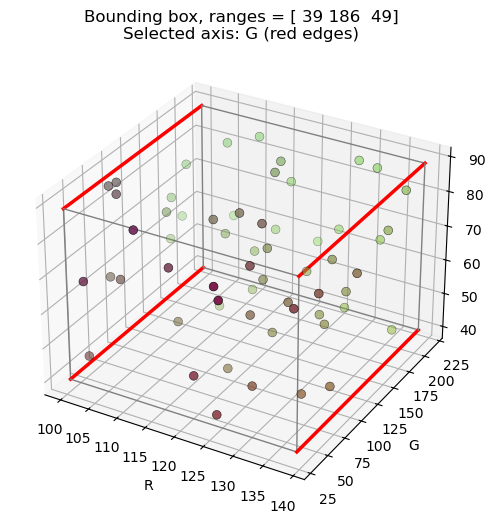

In [17]:
def plot_bounding_box(colors, value_max=255):
    """Draw the colors as points in RGB space with their bounding box and split axis."""
    colors = np.asarray(colors)
    mins, maxs = bounding_box(colors)
    axis = find_split_axis(colors)
    names = ["R", "G", "B"]

    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(projection="3d")

    # Each point is drawn in its own color
    ax.scatter(colors[:, 0], colors[:, 1], colors[:, 2],
               c=colors / value_max, s=40, edgecolors="black", linewidths=0.4)

    # The 8 corners of the box: min or max for each channel
    corners = np.array(list(product(*zip(mins, maxs))))

    # Two corners that differ in exactly one coordinate form an edge (12 edges)
    for i in range(8):
        for j in range(i + 1, 8):
            diff = corners[i] != corners[j]
            if diff.sum() == 1:
                is_split_axis = diff[axis]
                ax.plot(*zip(corners[i], corners[j]),
                        color="red" if is_split_axis else "gray",
                        linewidth=2.5 if is_split_axis else 1)

    ax.set_xlabel("R"); ax.set_ylabel("G"); ax.set_zlabel("B")
    ax.set_title(f"Bounding box, ranges = {axis_ranges(colors)}\n"
                 f"Selected axis: {names[axis]} (red edges)")
    plt.show()


# Example color set that is spread widely along the green channel
rng = np.random.default_rng(0)
demo = np.column_stack([rng.integers(100, 140, 60),   # R: narrow
                        rng.integers(20, 230, 60),    # G: wide
                        rng.integers(40, 90, 60)])    # B: narrow
plot_bounding_box(demo)

### How this step connects to the rest

The main loop (Task 5) calls `find_split_axis` for the box it wants to split and passes the returned axis to Task 4, which sorts the colors along that axis and cuts at the weighted median. `axis_ranges` is also available to the main loop, for example to skip boxes that contain a single color.

The frequency weights from Task 2 are not used here: the bounding box depends only on which colors are present, not on how often they occur.

## Task 4: Radix List Sort and Median Split

*Author: Elif Hilal Kırer*

The colors of a box are sorted along the axis chosen by Task 3. Because the values are small integers (0 to 31), a radix list sort is used: each color is dropped into the bucket of its value and the buckets are read in order. The box is then cut at the weighted median, the point where half of the *pixels* (not half of the colors) lie on each side.

**Input:** `colors`, `counts` and the split axis.
**Output:** two boxes, each as a `(colors, counts)` pair.

In [20]:
def split_box(colors, counts, axis):
    """
    Sort the colors along `axis` and cut them where half of the pixels
    are on each side (the weighted median).

    colors : (M, 3) unique colors in the box
    counts : (M,) number of pixels of each color
    axis   : 0 = R, 1 = G, 2 = B (chosen by Task 3)

    Returns (lower_colors, lower_counts), (upper_colors, upper_counts).
    """
    if len(colors) < 2:
        raise ValueError("a box needs at least 2 colors to be split")

    # radix list sort: the values are small integers (0-31), so we drop
    # each color's index into the bucket of its value and read the buckets in order
    values = colors[:, axis]
    buckets = [[] for _ in range(values.max() + 1)]
    for i, v in enumerate(values):
        buckets[v].append(i)
    order = [i for bucket in buckets for i in bucket]

    colors = colors[order]
    counts = counts[order]

    # add up pixels until we reach half of the total
    half = counts.sum() / 2
    seen = 0
    cut = 0
    while seen < half:
        seen += counts[cut]
        cut += 1

    # leave at least one color on each side
    cut = min(cut, len(colors) - 1)

    return (colors[:cut], counts[:cut]), (colors[cut:], counts[cut:])

### Tests for Task 4

In [22]:
# four colors that differ only in red, in mixed order
colors = np.array([[3, 0, 0],
                   [1, 0, 0],
                   [4, 0, 0],
                   [2, 0, 0]])

# equal counts -> cut in the middle, sorted by red
(low, _), (high, _) = split_box(colors, np.array([1, 1, 1, 1]), axis=0)
print("equal counts:", low[:, 0], "|", high[:, 0])
assert low[:, 0].tolist() == [1, 2]

# red=4 has most of the pixels -> it ends up alone on the upper side
(low, _), (high, _) = split_box(colors, np.array([1, 1, 10, 1]), axis=0)
print("heavy color :", low[:, 0], "|", high[:, 0])
assert high[:, 0].tolist() == [4]

# one color has almost all pixels -> neither side may be empty
(low, _), (high, _) = split_box(colors[:2], np.array([100, 1]), axis=0)
assert len(low) == 1 and len(high) == 1

print("all tests passed")

equal counts: [1 2] | [3 4]
heavy color : [1 2 3] | [4]
all tests passed


## Task 5: Box Orchestration and Final Palette

*Author: Fatma Hepsen Çakır*

The main loop starts with one box that holds all colors and keeps the boxes in a queue. Each turn it takes a box from the front, asks Task 3 for the split axis, lets Task 4 cut the box, and puts the two halves at the back of the queue. It stops when there are `K` boxes. The representative of each box is the average of its colors, weighted by pixel count.

**Input:** `colors`, `counts`, the target `K`, and the Task 3 and Task 4 functions.
**Output:** `(K, 3)` palette. The values are still on the 5-bit scale (0 to 31); `to_8bit` from Task 2 maps them back to 0 to 255.

In [24]:
def run_median_cut(colors, counts, K, find_split_axis_fn, split_box_fn):
  """Task 5: Box Orchestration and Final Palette Computation (Median Cut).

  Parameters:
  - colors: matrix of unique 5-bit colors from Task 2 (M, 3)
  - counts: pixel frequency weights from Task 2 (M,)
  - K: target number of colors (e.g. 256)
  - find_split_axis_fn: axis selection function of Task 3 (find_split_axis)
  - split_box_fn: box splitting function of Task 4
  """
  # At the start, all colors and their frequencies are put in the queue as a single box
  boxes = deque([(colors, counts)])

  # Keep looping until the number of boxes reaches K
  while len(boxes) < K:
    current_colors, current_freqs = boxes.popleft()

    # A box with 1 or 0 colors cannot be split, so put it back
    if len(current_colors) <= 1:
      boxes.append((current_colors, current_freqs))
      if all(len(c) <= 1 for c, _ in boxes):
        break
      continue

    # 1. Call Task 3: find the widest axis (0: R, 1: G, 2: B)
    axis = find_split_axis_fn(current_colors)

    # 2. Call Task 4: split the box in two at the median point along that axis
    left_box, right_box = split_box_fn(current_colors, current_freqs, axis)

    # Add the two resulting sub-boxes to the queue
    boxes.append(left_box)
    boxes.append(right_box)

  # 3. Final palette: take the frequency-weighted RGB average of each box
  palette = []
  for box_colors, box_freqs in boxes:
    if len(box_colors) == 0:
      palette.append([0, 0, 0])
    else:
      # Frequency-weighted average (numpy average)
      weighted_avg = np.average(box_colors, axis=0, weights=box_freqs)
      palette.append(np.round(weighted_avg))

  return np.array(palette, dtype=np.uint8)

### Test for Task 5

This test was written before integration, so it uses simple stand-ins for the Task 3 and Task 4 functions.

In [26]:
def test_task5():
  print("Starting the Task 5 test with mock data...")

  # Mock colors and frequencies
  mock_colors = np.random.randint(0, 32, size=(100, 3), dtype=np.uint8)
  mock_counts = np.random.randint(1, 20, size=(100,), dtype=np.uint32)

  def mock_find_split_axis(colors):
    ranges = np.ptp(colors, axis=0)
    return int(np.argmax(ranges))

  def mock_split_box(colors, freqs, axis):
    sorted_idx = np.argsort(colors[:, axis])
    c_sorted = colors[sorted_idx]
    f_sorted = freqs[sorted_idx]
    mid = len(c_sorted) // 2
    return (c_sorted[:mid], f_sorted[:mid]), (c_sorted[mid:], f_sorted[mid:])

  K_target = 16
  final_palette = run_median_cut(
      mock_colors,
      mock_counts,
      K=K_target,
      find_split_axis_fn=mock_find_split_axis,
      split_box_fn=mock_split_box,
  )

  print("Test completed successfully, no errors.")
  print(f"Palette shape for target K={K_target}: {final_palette.shape}")
  assert final_palette.shape == (K_target, 3)


test_task5()

Starting the Task 5 test with mock data...
Test completed successfully, no errors.
Palette shape for target K=16: (16, 3)


## Integration Tests: Data Types and Edge Cases

*Author: Ceren Tayran*

Each task was first tested on its own with mock data. These tests check that the tasks also work **together**: that the output of one task has the type, shape and value range the next task expects, and that the chain does not break in unusual cases.

| Test | What is checked |
|---|---|
| 1 | Task 1 turns grayscale and RGBA versions of the photo into RGB with shape `(H, W, 3)` and type `uint8` |
| 2 | Task 2 accepts `uint8` input without overflow, returns colors in 0 to 31 and counts that add up to the number of pixels |
| 3 | An image with a single color: the loop stops and returns a one-color palette |
| 4 | An image with fewer colors than `K`: the palette has one row per color |
| 5 | `K = 1`: the single palette color is the pixel-weighted mean of all colors |
| 6 | Every palette color lies inside the bounding box of the colors (Task 3) |
| 7 | `to_8bit` maps the palette back to `uint8` values in 0 to 255 |

Tests 1, 2, 5, 6 and 7 use the test photo. Tests 3 and 4 need images with only one or three colors, which no real photo has, so those two use small hand-written pixel arrays.

In [28]:
import tempfile

def median_cut_palette(pixels, k):
    """Run Tasks 2 to 5 on an (N, 3) pixel array and return colors, counts and the 5-bit palette."""
    colors, counts = quantize_and_histogram(pixels)
    palette5 = run_median_cut(colors, counts, k, find_split_axis, split_box)
    return colors, counts, palette5


# Test 1: Task 1 converts grayscale and RGBA versions of the photo to RGB
photo = load_rgb_image(IMAGE_PATH)
h, w, _ = photo.shape
with tempfile.TemporaryDirectory() as tmp:
    for mode in ("L", "RGBA"):
        path = Path(tmp) / f"photo_{mode}.png"
        Image.open(IMAGE_PATH).convert(mode).save(path)
        rgb = load_rgb_image(path)
        assert rgb.shape == (h, w, 3) and rgb.dtype == np.uint8, (mode, rgb.shape, rgb.dtype)
        assert flatten_pixels(rgb).shape == (h * w, 3)
print("Test 1 passed: grayscale and RGBA images are converted to (H, W, 3) uint8")

# Test 2: Task 2 on the uint8 pixels of the photo, plus the extreme values 0 and 255
pixels = flatten_pixels(photo).copy()
pixels[:2] = [[0, 0, 0], [255, 255, 255]]
colors, counts = quantize_and_histogram(pixels)
assert colors.min() == 0 and colors.max() == 31
assert counts.sum() == len(pixels)
print("Test 2 passed: values stay in 0-31 and every pixel is counted once")

# Test 3: single-color image -> the loop must stop with a one-color palette
single = np.full((100, 3), 200, dtype=np.uint8)
colors, counts, palette5 = median_cut_palette(single, 16)
assert palette5.shape == (1, 3)
assert (palette5[0] == 200 >> 3).all()
print("Test 3 passed: single-color image gives a 1-color palette")

# Test 4: fewer colors than K -> one palette entry per color
three = np.array([[0, 0, 0], [255, 0, 0], [0, 0, 255]] * 30, dtype=np.uint8)
colors, counts, palette5 = median_cut_palette(three, 16)
assert palette5.shape == (3, 3)
assert sorted(map(tuple, palette5)) == sorted(map(tuple, colors))
print("Test 4 passed: 3-color image with K=16 gives exactly those 3 colors")

# Test 5: K = 1 -> the palette is the pixel-weighted mean of all colors
colors, counts, palette5 = median_cut_palette(pixels, 1)
expected = np.round(np.average(colors, axis=0, weights=counts))
assert palette5.shape == (1, 3) and (palette5[0] == expected).all()
print("Test 5 passed: K=1 gives the weighted mean color", palette5[0])

# Test 6: every palette color lies inside the bounding box of the colors
colors, counts, palette5 = median_cut_palette(pixels, 32)
mins, maxs = bounding_box(colors)
assert palette5.shape == (32, 3)
assert ((palette5 >= mins) & (palette5 <= maxs)).all()
print("Test 6 passed: all 32 palette colors are inside the bounding box")

# Test 7: back to 8 bits
palette = to_8bit(palette5)
assert palette.dtype == np.uint8 and palette.min() >= 0 and palette.max() <= 255
print("Test 7 passed: to_8bit returns uint8 values in 0-255")

print("\nAll integration tests passed.")

Test 1 passed: grayscale and RGBA images are converted to (H, W, 3) uint8
Test 2 passed: values stay in 0-31 and every pixel is counted once
Test 3 passed: single-color image gives a 1-color palette
Test 4 passed: 3-color image with K=16 gives exactly those 3 colors
Test 5 passed: K=1 gives the weighted mean color [15 13  9]
Test 6 passed: all 32 palette colors are inside the bounding box
Test 7 passed: to_8bit returns uint8 values in 0-255

All integration tests passed.


## Full Pipeline on a Real Photo

Here the five tasks are chained. The output of each task is passed directly to the next one, and `run_median_cut` receives the real `find_split_axis` (Task 3) and `split_box` (Task 4).

In [30]:
# Task 1: image -> (N, 3) pixels
image = load_rgb_image(IMAGE_PATH)
pixels = flatten_pixels(image)

# Task 2: pixels -> unique 15-bit colors and their pixel counts
colors, counts = quantize_and_histogram(pixels)

# Tasks 3, 4, 5: median cut -> palette on the 5-bit scale, then back to 0-255
palette5 = run_median_cut(colors, counts, K, find_split_axis, split_box)
palette = to_8bit(palette5)

print("Image shape            :", image.shape)
print("Number of pixels       :", len(pixels))
print("Unique colors (24-bit) :", len(np.unique(pixels, axis=0)))
print("Unique colors (15-bit) :", len(colors))
print("Palette shape          :", palette.shape)

Image shape            : (512, 768, 3)
Number of pixels       : 393216
Unique colors (24-bit) : 72079
Unique colors (15-bit) : 4732
Palette shape          : (256, 3)


### Checks

- Every pixel must be counted exactly once in the histogram.
- The 15-bit colors must be in the range 0 to 31.
- The palette must have `K` rows, unless the image has fewer than `K` different colors.

In [32]:
assert pixels.shape == (image.shape[0] * image.shape[1], 3)
assert counts.sum() == len(pixels)
assert colors.min() >= 0 and colors.max() <= 31
assert palette.shape == (min(K, len(colors)), 3)
print("All pipeline checks passed.")

All pipeline checks passed.


### The first split on real data

Task 3 applied to the whole histogram: the box that encloses all colors of the photo, and the axis along which median cut makes its first cut.

Ranges of the first box: [31 31 31]


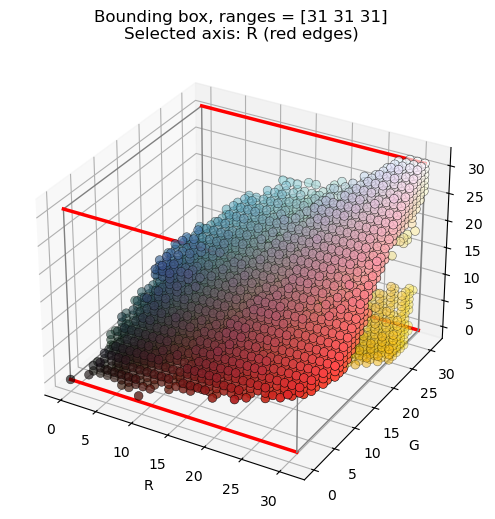

In [34]:
print("Ranges of the first box:", axis_ranges(colors))
plot_bounding_box(colors, value_max=31)

### The palette

The photo next to the `K` colors selected for it. Mapping every pixel to its nearest palette color (Phase C) and dithering (Phase D) are the next steps of the project.

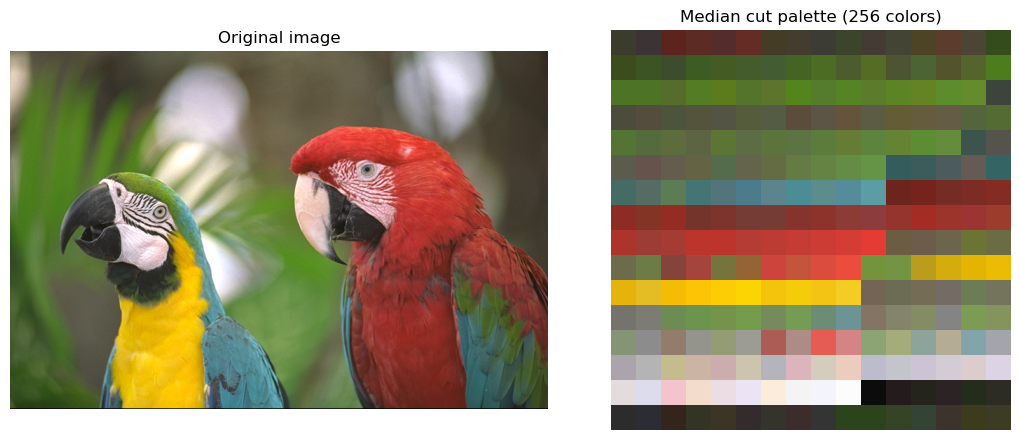

In [36]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.imshow(image)
ax1.set_title("Original image")
ax1.axis("off")

# Lay the palette out on a grid, 16 colors per row; unused cells stay white
cols = 16
rows = int(np.ceil(len(palette) / cols))
grid = np.full((rows * cols, 3), 255, dtype=np.uint8)
grid[:len(palette)] = palette
ax2.imshow(grid.reshape(rows, cols, 3))
ax2.set_title(f"Median cut palette ({len(palette)} colors)")
ax2.axis("off")

plt.tight_layout()
plt.show()

## Effect of K: Palette and Image Comparison

*Author: Ceren Tayran*

The number of palette colors `K` is the main parameter of median cut. This section runs the pipeline for several values of `K` on the same photo and shows the results side by side, so the effect of `K` can be seen directly: with few colors the smooth areas break into visible bands, and as `K` grows the image gets closer to the original.

The steps for each `K`:

1. Run median cut (Tasks 2 to 5) on the histogram of the photo to get a `K`-color palette.
2. Map every pixel to its nearest palette color (Phase C).
3. Rebuild the image from the palette and the pixel indices.

### Temporary stand-in for Phase C

Mapping pixels to their nearest palette color is Phase C, implemented by Gizem Bayram. Until her function is added to this notebook, the cell below defines a simple stand-in with the agreed interface:

`map_to_palette(pixels, palette) -> indices`

- `pixels`: `(N, 3)` array, values 0 to 255
- `palette`: `(K, 3)` array, values 0 to 255 (the output of `to_8bit`)
- `indices`: `(N,)` array; `indices[i]` is the row of the palette closest to pixel `i`

The stand-in is only defined when no `map_to_palette` exists yet. Once the real function is placed above this section, it is used automatically and this cell does nothing.

In [39]:
if "map_to_palette" not in globals():

    def map_to_palette(pixels, palette, chunk_size=50_000):
        """TEMPORARY stand-in for Phase C: exhaustive nearest-color search.

        Squared RGB distance as in Heckbert (1982). Pixels are processed in
        chunks so the (chunk, K) distance matrix stays small in memory.
        """
        pixels = np.asarray(pixels, dtype=np.int32)
        palette = np.asarray(palette, dtype=np.int32)
        indices = np.empty(len(pixels), dtype=np.int32)
        for start in range(0, len(pixels), chunk_size):
            block = pixels[start:start + chunk_size]
            diff = block[:, None, :] - palette[None, :, :]   # (chunk, K, 3)
            dist = (diff ** 2).sum(axis=2)                     # (chunk, K)
            indices[start:start + chunk_size] = dist.argmin(axis=1)
        return indices

    print("Using the TEMPORARY stand-in for map_to_palette.")
else:
    print("Using the Phase C map_to_palette defined above.")

Using the TEMPORARY stand-in for map_to_palette.


### Running the comparison

`quantize_with_k` returns the 8-bit palette and the rebuilt image for one value of `K`. The histogram is computed once and reused, because it does not depend on `K`.

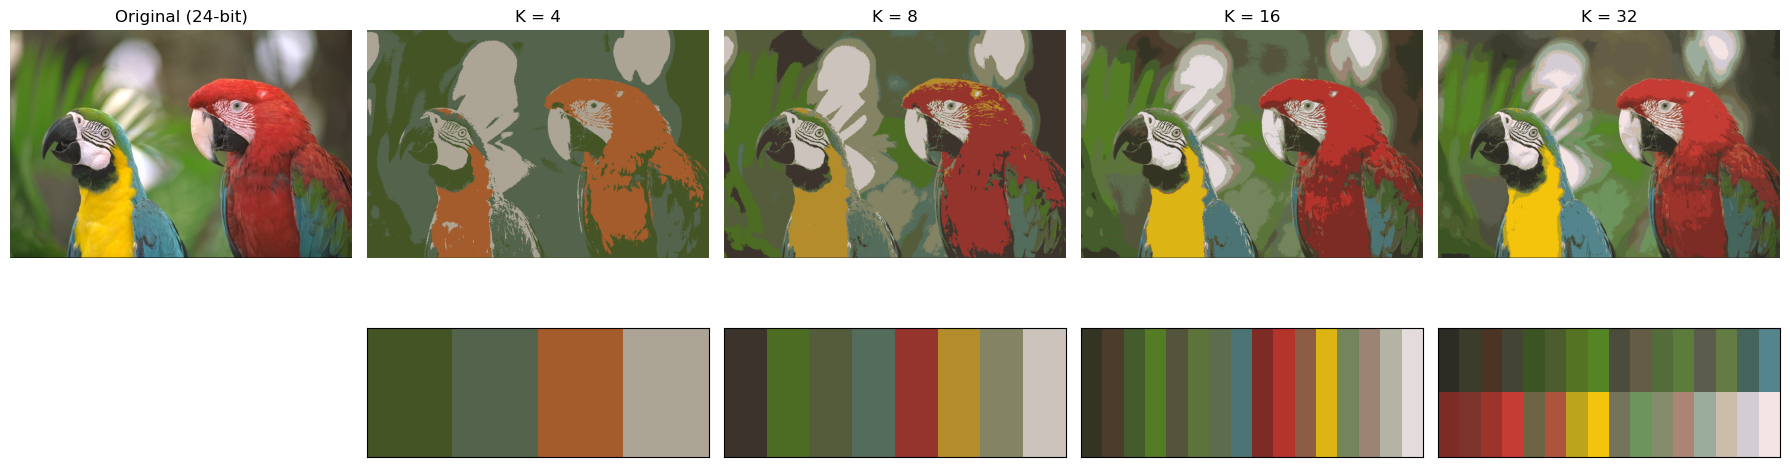

In [41]:
def quantize_with_k(image, colors, counts, k):
    """Median cut with k colors, then rebuild the image from the palette.

    Returns (palette, quantized_image); palette is (k', 3) uint8 with k' <= k.
    """
    palette5 = run_median_cut(colors, counts, k, find_split_axis, split_box)
    palette = to_8bit(palette5)
    indices = map_to_palette(flatten_pixels(image), palette)
    quantized = palette[indices].reshape(image.shape)
    return palette, quantized


def draw_palette(ax, palette, cols=16):
    """Draw a palette as a grid of color cells; unused cells stay white."""
    cols = min(cols, len(palette))
    rows = int(np.ceil(len(palette) / cols))
    grid = np.full((rows * cols, 3), 255, dtype=np.uint8)
    grid[:len(palette)] = palette
    # aspect="auto" stretches the grid to fill the axis, so every palette has the same size
    ax.imshow(grid.reshape(rows, cols, 3), aspect="auto")
    ax.set_xticks([]); ax.set_yticks([])


K_VALUES = [4, 8, 16, 32]

image = load_rgb_image(IMAGE_PATH)
colors, counts = quantize_and_histogram(flatten_pixels(image))
results = {k: quantize_with_k(image, colors, counts, k) for k in K_VALUES}

fig, axes = plt.subplots(2, len(K_VALUES) + 1, figsize=(18, 6),
                         gridspec_kw={"height_ratios": [4, 1]})

axes[0, 0].imshow(image)
axes[0, 0].set_title("Original (24-bit)")
axes[1, 0].axis("off")

for col, k in enumerate(K_VALUES, start=1):
    palette, quantized = results[k]
    axes[0, col].imshow(quantized)
    axes[0, col].set_title(f"K = {k}")
    draw_palette(axes[1, col], palette)

for ax in axes[0]:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Zoomed view

Banding is easiest to see in smooth areas. The crop below shows the blurred background next to the green parrot's head, where the colors change slowly.

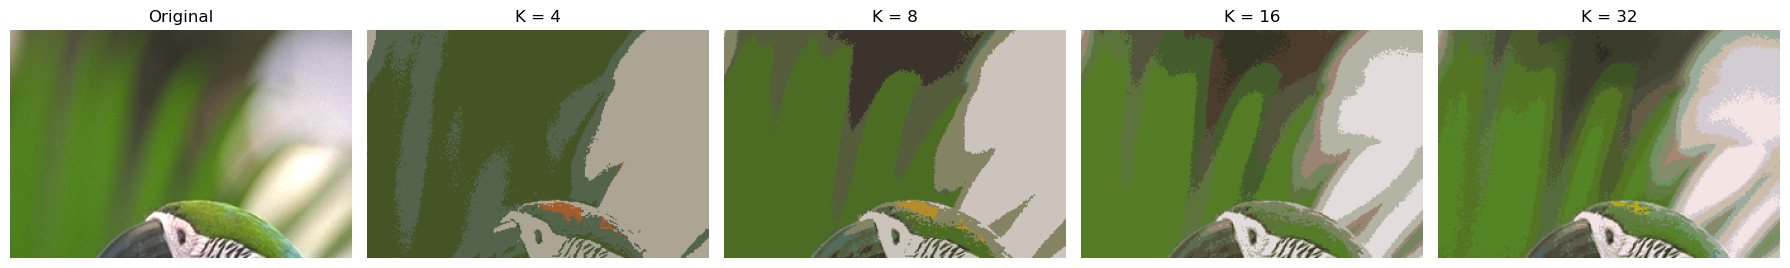

In [43]:
# Crop window (rows, columns) on the 512 x 768 photo
r0, r1, c0, c1 = 40, 220, 20, 290

fig, axes = plt.subplots(1, len(K_VALUES) + 1, figsize=(18, 3.6))
axes[0].imshow(image[r0:r1, c0:c1])
axes[0].set_title("Original")
for ax, k in zip(axes[1:], K_VALUES):
    ax.imshow(results[k][1][r0:r1, c0:c1])
    ax.set_title(f"K = {k}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Median Cut Step by Step in RGB Space

*Author: Ceren Tayran*

The previous sections show only the final palette. Here the splitting itself is drawn: the colors of the photo are plotted in RGB space (on the 5-bit scale, 0 to 31), and the boxes are shown when there are 2, 4, 8 and 16 of them. Each color is drawn in the representative color of the box it belongs to, so every stage also shows the palette at that point.

`run_median_cut` (Task 5) returns only the final palette, not the boxes. To keep Task 5 unchanged, `median_cut_stages` repeats the same loop for visualization: it takes boxes from the front of a queue, splits them with `find_split_axis` (Task 3) and `split_box` (Task 4), puts the halves at the back, and saves a copy of the boxes whenever their number reaches one of the requested stages. Because it uses the same queue order, its boxes are the same as the ones inside Task 5.

In [45]:
from collections import deque

def median_cut_stages(colors, counts, stages):
    """Repeat the median cut loop of Task 5 and record the boxes at each stage.

    Returns {number_of_boxes: [(box_colors, box_counts), ...]} for every value in
    `stages` that can be reached. Used only for visualization.
    """
    boxes = deque([(colors, counts)])
    snapshots = {}
    target = max(stages)
    while True:
        if len(boxes) in stages:
            snapshots[len(boxes)] = list(boxes)
        if len(boxes) >= target or all(len(c) <= 1 for c, _ in boxes):
            break
        box_colors, box_counts = boxes.popleft()
        if len(box_colors) <= 1:          # cannot be split: put it back
            boxes.append((box_colors, box_counts))
            continue
        axis = find_split_axis(box_colors)
        low, high = split_box(box_colors, box_counts, axis)
        boxes.append(low)
        boxes.append(high)
    return snapshots


def draw_box_edges(ax, mins, maxs, color="black", linewidth=0.8):
    """Draw the 12 edges of an axis-aligned box in a 3D axis."""
    corners = np.array(list(product(*zip(mins, maxs))))
    for i in range(8):
        for j in range(i + 1, 8):
            if (corners[i] != corners[j]).sum() == 1:
                ax.plot(*zip(corners[i], corners[j]), color=color, linewidth=linewidth)


STAGES = [1, 2, 4, 8, 16]
snapshots = median_cut_stages(colors, counts, STAGES)

# Check: the stage with the most boxes gives the same palette as Task 5
k_max = max(snapshots)
means = np.array([np.round(np.average(c, axis=0, weights=n)) for c, n in snapshots[k_max]])
assert (means == run_median_cut(colors, counts, k_max, find_split_axis, split_box)).all()
print("Stages reached:", sorted(snapshots), "| matches Task 5 for K =", k_max)

Stages reached: [1, 2, 4, 8, 16] | matches Task 5 for K = 16


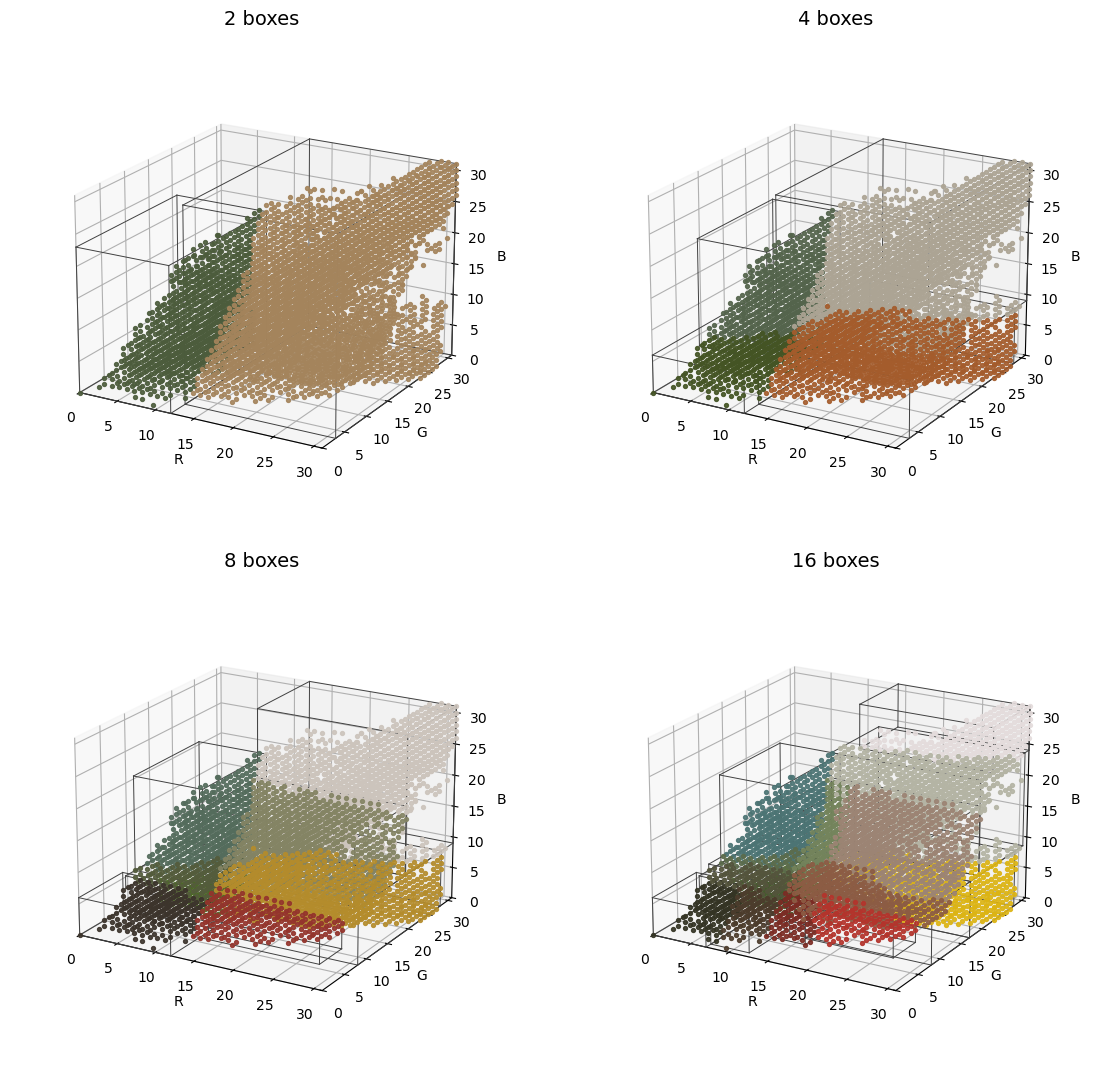

In [46]:
fig = plt.figure(figsize=(12, 11))

for pos, k in enumerate(sorted(snapshots)[1:], start=1):   # 2, 4, 8, 16 boxes
    ax = fig.add_subplot(2, 2, pos, projection="3d")
    for box_colors, box_counts in snapshots[k]:
        mean = np.average(box_colors, axis=0, weights=box_counts)
        ax.scatter(box_colors[:, 0], box_colors[:, 1], box_colors[:, 2],
                   color=to_8bit(np.round(mean)) / 255, s=8, alpha=0.9,
                   depthshade=False)
        mins, maxs = bounding_box(box_colors)
        draw_box_edges(ax, mins, maxs, color="0.25", linewidth=0.7)
    ax.set_xlim(0, 31); ax.set_ylim(0, 31); ax.set_zlim(0, 31)
    ax.set_xlabel("R"); ax.set_ylabel("G"); ax.set_zlabel("B")
    ax.set_box_aspect(None, zoom=0.85)
    ax.set_title(f"{k} boxes", fontsize=14)
    ax.view_init(elev=20, azim=-60)

plt.tight_layout()
plt.show()

Reading the figure: the 1-box stage is left out, because all colors then share one representative, the average color of the photo. Each split cuts a box along its widest axis (Task 3) at the weighted median (Task 4). Dense regions of the color cloud, such as the many greens of the background, are cut into many small boxes, while sparse regions keep large boxes. This is how median cut spends more palette colors where the photo has more pixels.